# <center>**M2 Bio-informatique - Projet MLG**<center>
Réalisé par Théo Brugel et Benjamin Theuleau

# Contexte de l’étude et objectifs
Depuis le début de l’année 2026, 343 cas de paludisme ont été enregistrés sur l’île de Mayotte, dont 76 acquis localement et 238 importés, majoritairement en provenance des Comores (Bulletin Surveillance Regionale Mayotte). Le paludisme est transmis à l’être humain par la piqûre d’un moustique du genre Anopheles, lui-même infecté par le parasite du genre Plasmodium après avoir piqué un humain impaludé.<br>
Les modifications de l'occupation du sol, notamment l'urbanisation, la disparition de la végétation ou la transformation des espaces agricoles, peuvent influencer les conditions environnementales favorables à certaines espèces de moustiques. Les Anopheles sont fréquemment associés aux habitats aquatiques, aux zones agricoles/pastorales et à des conditions paysagères favorables aux gîtes larvaires ; les études de télédétection montrent notamment des associations avec l’altitude, l’humidité du sol, la distance aux cours d’eau, le NDVI et les classes d’occupation du sol.

<i>Question à laquelle vous devez répondre : Dans quels contextes paysagers les moustiques du genre Anopheles sont-ils détectés en 2024, et peut-on prédire leur présence sur l’ensemble de la zone d’étude à partir de variables environnementales issues d’images satellites.</i>

À partir de 2 images satellites Sentinel-2 acquises à des dates différentes, vous devrez analyser et quantifier l'évolution de l'occupation du sol à Mayotte, avec une attention particulière portée aux environnements de vis des moustiques.<br>
Cet exercice vous fera mobiliser les méthodes de traitement d'images et de machine learning étudiées en TP afin de produire une analyse spatiale argumentée des changements environnementaux pouvant expliquer en partie la présence du vecteur et d’en prédire sa probable présence sur les zones ou cleui-ci n’a pas été enregistré.

# Organisation des répertoires
|_ MLG/  
&emsp;|_ projet_MLG.ipynb  
&emsp;|_ images/  
&emsp;&emsp;|_ Sentinel2_2019/  
&emsp;&emsp;|_ Sentinel2_2024/  
&emsp;&emsp;|_ Inventaire.tif

# Librairies

In [2]:
import numpy as np
import os
import rastereasy as re
import sklearn as skl

# Préparation des images

Les deux images fournies sont au format Sentinel-2 du programme Copernicus de l'ESA. C'est-à-dire que nous disposons de deux dossiers (un par date d'image) contenant chaque bandes séparées.  
Pour pouvoir les utiliser dans la suite de notre projet, nous allons stacker les bandes et les rééchantillonner afin qu'elles soient toutes à une même résolution (ici 10m/pixel).  
Nous produirons ensuite une version découpée de nos images autour de la zone d'intérêt, la zone de recensement des moustiques (Inventaire.tif) car, *a priori*, c'est seulement celle-ci qui nous intéresse. Nous garderons tout de même une version complète centrée sur l'île entière au cas où elle nous serve dans la suite de ce projet.

In [43]:
# Pour chacune des deux dates, nous stackons l'ensemble des bandes au sein d'une seule image

# variables
# Chemin vers les images
s2_folder = ["./images/Sentinel2_2019/GRANULE/L2A_T38LNL_A021510_20190805T072207/IMG_DATA", "./images/Sentinel2_2024/GRANULE/L2A_T38LNL_A038985_20240823T072200/IMG_DATA",]
resolutions = {"R10m": ["B02", "B03", "B04", "B08",], "R20m": ["B01", "B05", "B06", "B07", "B8A", "B11", "B12",],}
# Liste des bandes
bands_s2_name = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12",]
bands_name = {"AC":1, "B":2, "G":3, "R":4, "RE1":5, "RE2":6, "RE3":7, "NIR":8, "NNIR":9, "SWIR1":10, "SWIR2":11,}

# Création des deux images stackées
years = [2019, 2024,]
for path, year in zip(s2_folder, years):
    # Liste de l'ensemble des bandes contenues dans les dossiers pour les résolutions 10 et 20m
    band2add_R10 = os.listdir(f"{path}/R10m/")
    band2add_R20 = os.listdir(f"{path}/R20m/")

    mayotte = re.open(f"{path}/R20m/{band2add_R20[1]}").resample(10)

    # Pour chacun des deux dossiers, on parcours les bandes qu'on veut récupérer (cf bands_s2_name)
    # puis on les ajoutes au stack avec une résolution à 10m (native pour BGRNIR, rééchantillonnée pour les autres)
    for band in bands_s2_name[1:]:
        if band in resolutions["R10m"]:
            for img in band2add_R10:
                if ".aux.xml" not in img and band in img:
                    band2add = re.open(f"{path}/R10m/{img}")
                    mayotte.stack(band2add, inplace=True)

        elif band in resolutions["R20m"]:
            for img in band2add_R20:
                if ".aux.xml" not in img and band in img:
                    band2add_resampled = re.open(f"{path}/R20m/{img}").resample(10)
                    mayotte.stack(band2add_resampled, inplace=True)

    # On remet au propre le nom des bandes puis on enregistre le stack sur le disque dur
    mayotte.change_names(bands_name)
    mayotte.save(f"./images/mayotte_{year}.tif")

# Centrage et découpage des images sur l'île
islands = ["./images/mayotte_2019.tif", "./images/mayotte_2024.tif",]

for isle in islands:
    isle_resize = re.open(isle).crop(area = ((0, 4000), (0, 3500)))
    isle_resize.save(isle)

# Centrage et découpage des images sur la zone de piègeage
traps = re.open("./images/Inventaire.tif")

for isle, year in zip(islands, years):
    isle_trap_area, inventaire_resize = re.extract_common_areas(re.open(isle), traps)
    isle_trap_area.save(f"./images/traps_area_{year}.tif")
inventaire_resize.save("./images/inventaire_resize.tif")

# **Objectif 1 : exploration des images satellites**

## Caractéristiques principales des images

In [37]:
# Affichage des informations de chacune des deux images
mayotte_2019 = re.open("./images/traps_area_2019.tif")
mayotte_2024 = re.open("./images/traps_area_2024.tif")

print(mayotte_2019.info())
print(mayotte_2024.info())

- Size of the image:
   - Rows (height): 1447
   - Cols (width): 1757
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72944773, 45.09600656)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}


None
- Size of the image:
   - Rows (height): 1447
   - Cols (width): 1757
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72944773, 45.09600656)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}


None


| | <center>Sentinel2_2019<center> | <center>Sentinel2_2024<center> |
|-|-|-|
| <center>**Date d'acquisition**<center> | <center>05/08/2019<center> | <center>23/08/2024<center> |
| <center>**Résolution spatiale**<center> | <center>10 mètres<center> | <center>10 mètres<center> |
| <center>**Bandes spectrales**<center> |<center>Coastal Aerosol / Blue / Green /<br>Red / Red Edge 1,2,3 / Near Infra-Red /<br>Narrow Near Infra-Red / Shortwave Infra-Red 1,2<center>|<center>Coastal Aerosol / Blue / Green /<br>Red / Red Edge 1,2,3 / Near Infra-Red /<br>Narrow Near Infra-Red / Shortwave Infra-Red 1,2<center>|
| <center>**Dimensions**<center> | <center>1447x1757 pixels<br>soit 14,47x17,57 km<center> | <center>1447x1757 pixels<br>soit 14,47x17,57 km<center> |

## Visualisation des images

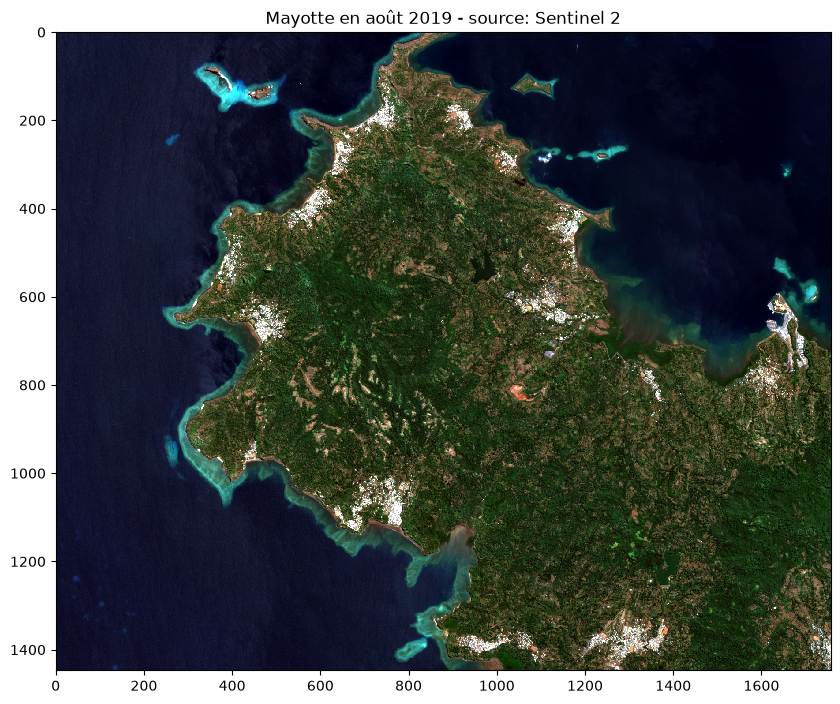

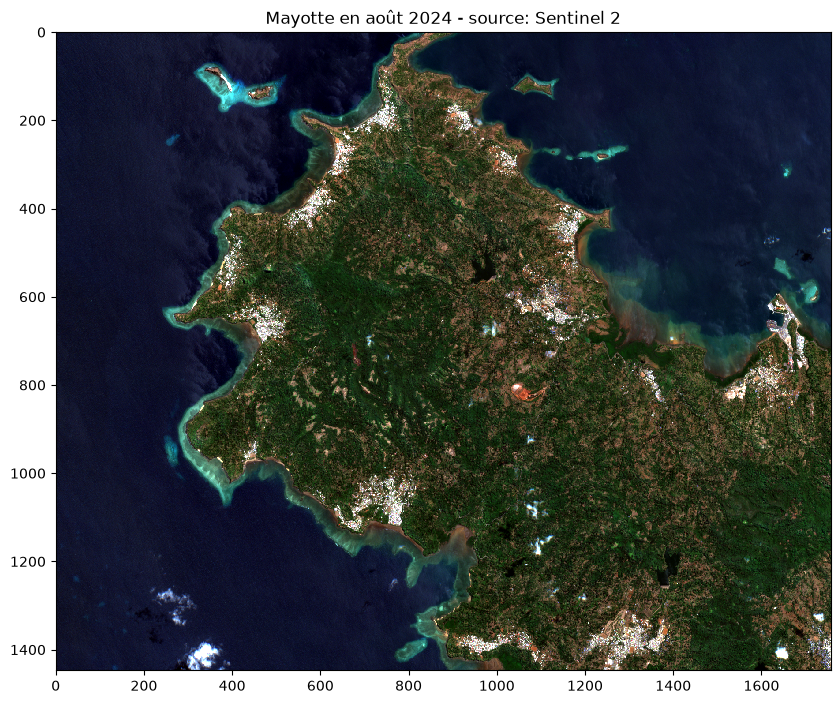

In [46]:
# Compositions colorées de Mayotte en 2019 et 2024
mayotte_2019.colorcomp(["R", "G", "B",], fig_size = (10,10), extent = "pixel", title = "Mayotte en août 2019 - source: Sentinel 2")
mayotte_2024.colorcomp(["R", "G", "B",], fig_size = (10,10), extent = "pixel", title = "Mayotte en août 2024 - source: Sentinel 2")

# **Objectif 2 : Calcul et comparaison des indicateurs spectraux**

# **Objectif 3 : Classification de l'occupation du sol**

# **Objectif 4 : Détection et quantification des changements**

# **Objectif 5 : Analyse environnementale à proximité des pièges à moustiques**

# **Objectif 6 : Risque et probabilité de présence (optionnel)**